<a href="https://colab.research.google.com/github/SlepenkovaDaria/Statistical_Experiments/blob/main/ttest_one_sample.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# **Формулировка задачи**
Фабрика производит шоколадные батончики. На этикетке указан чистый вес 50 граммов. По технологии допускаются случайные отклонения, но в среднем вес должен строго соответствовать 50 г (не меньше, чтобы не обманывать покупателей, и не больше, чтобы не терять прибыль).

Начальник цеха жалуется, что автомат для розлива начинки сбился, и батончики стали систематически тяжелее. Чтобы проверить это, мы взвесили случайную выборку из 10 батончиков, сошедших с линии за последний час.

*   Полученная выборка: [50.8, 51.2, 49.5, 50.3, 51.5, 50.9, 51.8, 50.1, 51.0, 50.6]

In [ ]:
X = np.array([50.8, 51.2, 49.5, 50.3, 51.5, 50.9, 51.8, 50.1, 51.0, 50.6])
print(f"Средний вес батончика: {round(np.mean(X), 2)}")

Средний вес батончика: 50.77


Гипотеза звучит так:

$$
H_0: EX = 50 \ \text{vs.} \ H_1: EX > 50
$$

Зафиксируем FPR = 0.05

Так как выборка мала, построим гистограмму и QQ-plot, применим критерий Шапиро-Уилка

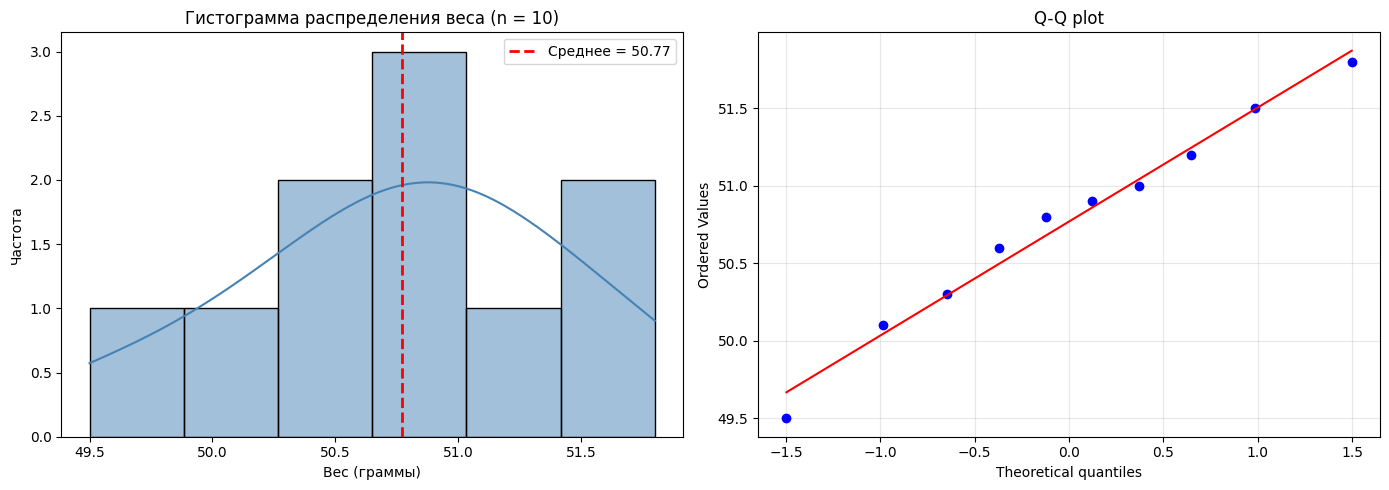

In [ ]:
fig, axes = plt.subplots(1, 2, figsize = (14, 5))

sns.histplot(X, kde = True, bins = 6, ax = axes[0], color = 'steelblue', edgecolor = 'black')
axes[0].axvline(np.mean(X), color = 'red', linestyle = '--', linewidth = 2,
                label = f'Среднее = {round(np.mean(X), 2)}')
axes[0].set_title('Гистограмма распределения веса (n = 10)', fontsize = 12)
axes[0].set_xlabel('Вec (граммы)')
axes[0].set_ylabel('Частота')
axes[0].legend()

stats.probplot(X, dist = 'norm', plot = axes[1])
axes[1].set_title('Q-Q plot', fontsize = 12)
axes[1].grid(True, alpha = 0.3)

plt.tight_layout()
plt.show()

In [ ]:
shapiro_stat, shapiro_p = stats.shapiro(X)
print(f'Статистика W: {round(shapiro_stat, 4)}')
print(f'p-value: {round(shapiro_p, 4)}')

Статистика W: 0.9866
p-value: 0.9907


*   На гитограмме распределение визуально симметрично
*   На QQ-plot эмпирические точки лежат близко к теоретической прямой, что говорит о соответсвии распределения нормальному
*   p-value > 0.05

Вывод: нет оснований отвергнуть гипотезу о нормальности распределения. Данные можно считать извлеченными из нормально распределенной генеральной совокупности







In [ ]:
mu_0 = 50
alpha = 0.05
n = 10
X_mean = np.mean(X)
X_std = np.std(X, ddof = 1)

t_stat, p_value = stats.ttest_1samp(X, mu_0, alternative = 'greater')
t_critical = stats.t.ppf(1 - alpha, n - 1)

print(f"Значение t-статистики: {round(t_stat, 3)}")
print(f"Значение p-value: {round(p_value, 5)}")


Значение t-статистики: 3.581
Значение p-value: 0.00296


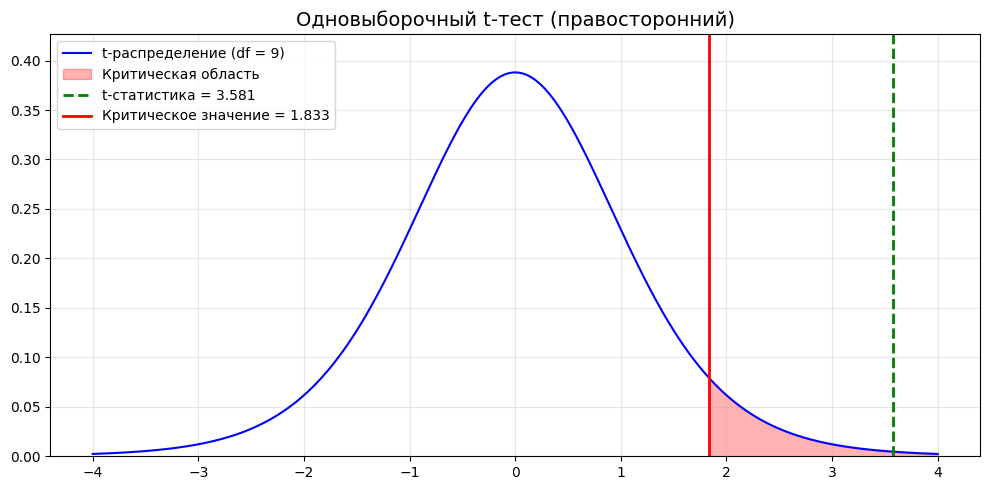

In [ ]:
fig, ax = plt.subplots(figsize = (10, 5))

x = np.linspace(-4, 4, 500)
y = stats.t.pdf(x, n - 1)
ax.plot(x, y, label = f't-распределение (df = {n - 1})', color = 'blue')

x_crit = np.linspace(t_critical, 4, 100)
y_crit = stats.t.pdf(x_crit, n - 1)
ax.fill_between(x_crit, 0, y_crit, color = 'red', alpha = 0.3, label = 'Критическая область')

ax.axvline(t_stat, color = 'green', linestyle = '--', linewidth = 2, label = f't-статистика = {round(t_stat, 3)}')
ax.axvline(t_critical, color = 'red', linestyle = '-', linewidth = 2, label = f'Критическое значение = {round(t_critical, 3)}')

ax.set_title('Одновыборочный t-тест (правосторонний)', fontsize = 14)
ax.legend()
ax.grid(True, alpha = 0.3)

y_max = np.max(y)
ax.set_ylim(0, y_max * 1.1)
plt.tight_layout()
plt.show()

$$p = 0.00296 < \alpha = 0.05$$

**Статистический вывод:**
Поскольку $t_{\text{набл}}$ попадает в критическую область (правее $t_{\text{крит}}$) и $p\text{-value} < \alpha$, мы **отвергаем нулевую гипотезу** $H_0: EX = 50$ в пользу альтернативной гипотезы $H_1: EX > 50$.

Средний вес батончиков в выборке ($\bar{x} = 50.77$ г) статистически значимо превышает заявленные 50 г. Разница составляет $0.77$ г и не является случайной.

**Практическая рекомендация:**
Рекомендуется вызвать наладчика для перенастройки оборудования, так как автомат систематически перевешивает продукцию, что приводит к перерасходу сырья и снижению прибыли предприятия.

In [ ]:
sem = X_std / np.sqrt(n)
t_critical_ci = stats.t.ppf(1 - alpha/2, n - 1)
margin = t_critical_ci * sem
CI_lower = X_mean - margin
CI_upper = X_mean + margin

print(f"Доверительный интервал для среднего: ({round(CI_lower, 5)}, {round(CI_upper, 5)})")

Доверительный интервал для среднего: (50.28359, 51.25641)


Так же при помощи метода Монте-Карло посмотрим мощность данного критерия:

In [ ]:
n_simulations = 10000
rejections = 0

for i in range(n_simulations):
    sample = np.random.normal(loc = X_mean, scale = X_std, size = n)
    t_stat, p_value = stats.ttest_1samp(sample, mu_0, alternative = 'greater')

    if p_value < alpha:
        rejections += 1

power = rejections / n_simulations

print(f"Мощность: {round(power, 5)}")

Мощность: 0.9532


Мощность составляет 95.3%, что является хорошим результатом.